# geo-embeddings-agents demo

A short tour of the results. Every cell reads files committed in this repository (`docs/results/`, `docs/figures/`, `docs/examples/`), so it runs without Earth Engine, Databricks or an API key. The code that produced those files is in `src/geo_embeddings/` and the README lists one command per step.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'docs' / 'results', ROOT / 'docs' / 'figures'
load = lambda name: json.loads((RES / f'{name}.json').read_text())

## 1. Land cover, validated on spatial blocks

A Random Forest on the 64 embedding values, 13 classes grouped from the USDA Cropland Data Layer. Cross-validation uses 10 km spatial blocks. The random split is shown only to make the point that it flatters the model.

In [2]:
spatial, random = load('rf_spatial10km'), load('rf_random')
def row(r, name):
    b = r['block_bootstrap']
    fmt = lambda m: f"{b[m]['value']:.3f} ({b[m]['ci'][0]:.3f} to {b[m]['ci'][1]:.3f})"
    return {'validation': name, 'overall accuracy (95% CI)': fmt('overall_accuracy'), 'kappa (95% CI)': fmt('kappa')}
pd.DataFrame([row(spatial, '10 km spatial blocks'), row(random, 'random split')]).set_index('validation')

,overall accuracy (95% CI),kappa (95% CI)
validation,,
10 km spatial blocks,0.891 (0.868 to 0.913),0.882 (0.857 to 0.904)
random split,0.955 (0.949 to 0.960),0.951 (0.944 to 0.957)


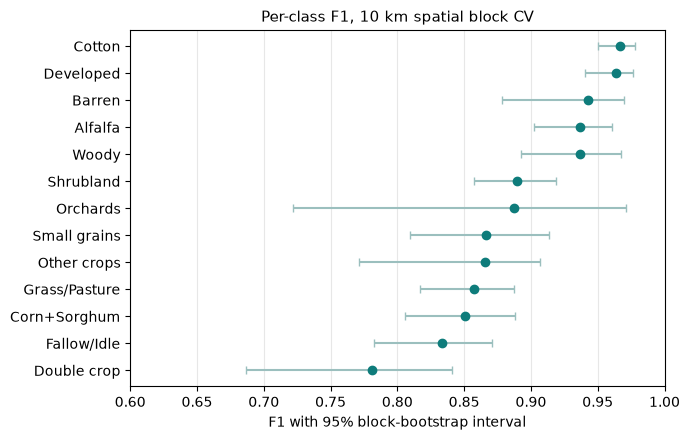

In [3]:
names = spatial['class_names']
f1 = pd.DataFrame([{'class': names[k], 'f1': v['value'], 'lo': v['ci'][0], 'hi': v['ci'][1], 'blocks': v['n_blocks']}
                   for k, v in spatial['block_bootstrap']['f1_per_class'].items()]).sort_values('f1')
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(f1.f1, f1['class'], xerr=[f1.f1 - f1.lo, f1.hi - f1.f1], fmt='o', color='#0E7C7B', ecolor='#9bbfbe', capsize=3)
ax.set_xlabel('F1 with 95% block-bootstrap interval'); ax.set_xlim(0.6, 1.0); ax.grid(axis='x', alpha=0.3)
ax.set_title('Per-class F1, 10 km spatial block CV', fontsize=11); plt.tight_layout(); plt.show()

Rare, clustered classes such as Orchards and Double crop have the widest intervals. Errors also follow the quality of the reference labels.

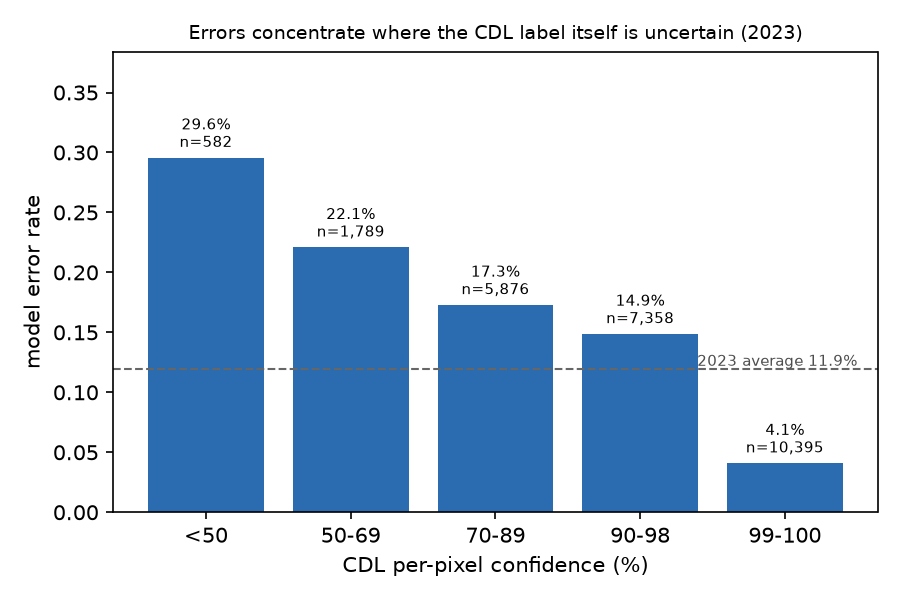

In [4]:
display(Image(filename=str(FIG / 'error_vs_cdl_confidence.png'), width=560))

## 2. Change between 2023 and 2024

The change score is one minus the cosine similarity of a place's 2023 and 2024 embeddings. AUC measures how well it separates each kind of CDL transition from places whose CDL class did not change.

In [5]:
ch = pd.DataFrame(load('change_2023_2024')['pure_both_years']).dropna(subset=['auc'])
ch[['transition', 'n', 'median_change', 'auc']].round(3).sort_values('auc', ascending=False).set_index('transition')

,n,median_change,auc
transition,,,
crop to crop,2982,0.439,0.984
crop <-> fallow,3647,0.375,0.973
farm <-> natural,4010,0.078,0.860
any change,14315,0.156,0.840
to/from developed,1097,0.031,0.597
natural to natural,2579,0.029,0.558


Farm changes are detected very well. Flips between natural classes sit near chance, which suggests many are relabeling rather than change on the ground.

## 3. Find places like this one

Share of the top 50 matches more than 10 km from the query that have the query's CDL class (30 queries per class, 2024). Lift compares that share with how common the class is in the county.

In [6]:
s = load('search_eval_2024')
pc = pd.DataFrame(s['per_class'])[['class_name', 'share_of_county', 'precision_beyond_10km', 'lift_beyond_10km']]
display(pc.round(3).sort_values('precision_beyond_10km', ascending=False).set_index('class_name'))
v = s['vector_search_vs_exact']
print(f"Databricks Vector Search vs exact search: mean top-{v['k']} overlap {v['mean_recall']:.2f} (min {v['min_recall']:.2f}), "
      f"median query latency {v['latency_ms_median']:.0f} ms from a laptop")

,share_of_county,precision_beyond_10km,lift_beyond_10km
class_name,,,
Shrubland,0.838,0.973,1.162
Cotton,0.018,0.925,51.319
Alfalfa,0.017,0.799,45.913
Small grains,0.005,0.789,162.898
Corn+Sorghum,0.006,0.768,138.832
Developed,0.027,0.622,22.639
Fallow/Idle,0.021,0.601,28.884
Orchards,0.001,0.467,518.286
Other crops,0.003,0.440,128.102


Databricks Vector Search vs exact search: mean top-50 overlap 0.84 (min 0.54), median query latency 246 ms from a laptop


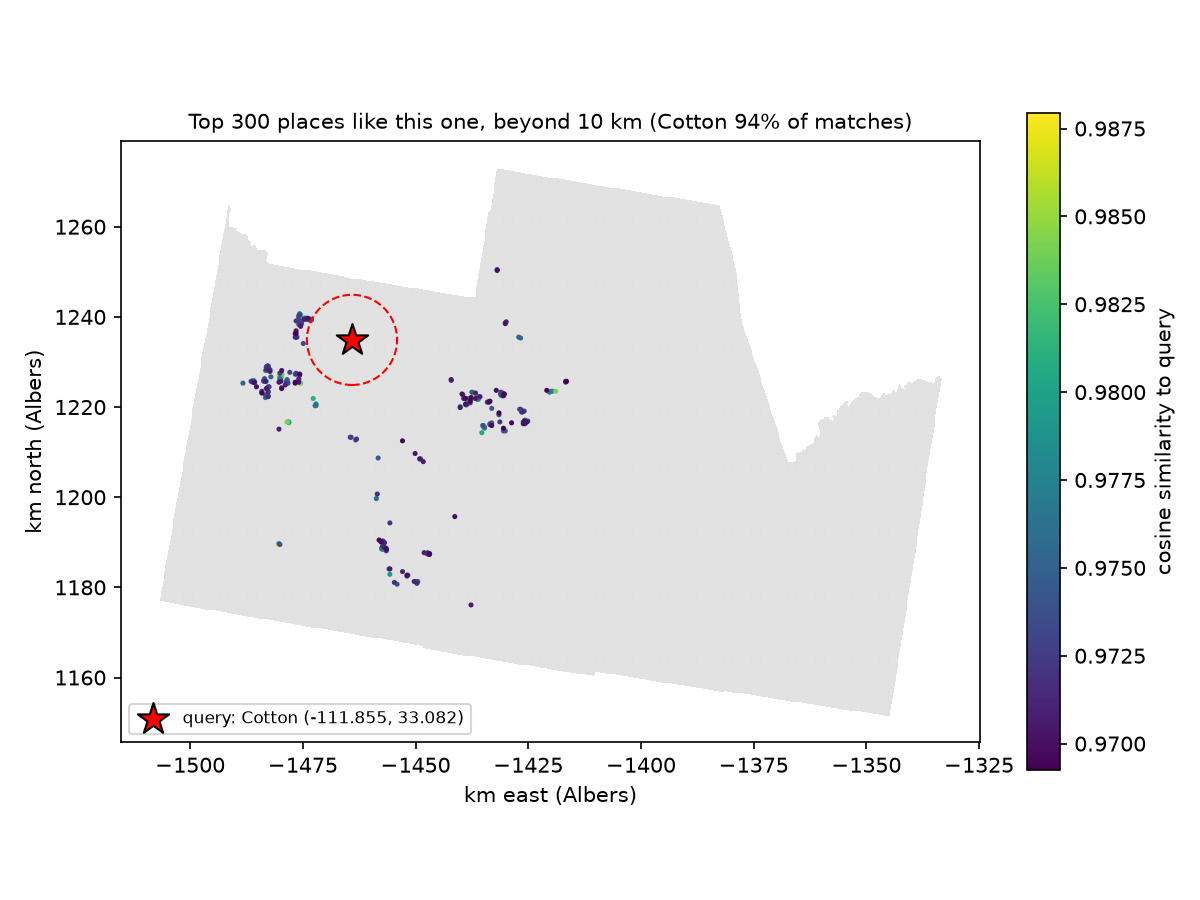

In [7]:
display(Image(filename=str(FIG / 'search_example_cotton.png'), width=640))

## 4. What the agents see

`python -m agents.demo` runs the agent team's read-only tools on three questions with no language model involved. Below is the evidence for the non-farm change question, where the strongest change outside farmland lines up with a 2024 MODIS burn that the CDL does not show.

# Where did land outside farms change most from 2023 to 2024, and why?

> **Scripted snapshot, no model involved.** These are the outputs of the agent team's read-only tools, run in a fixed order by `agents/demo.py` on 2026-11-13. A live run (`python -m agents.run`) lets Claude choose the tools and write the answer, with a validator agent checking it.

## 1. databricks-analyst · `change_hotspots(top_n=10, max_cropland_share=0.05)`

share_changed = share of 200 m nodes with embedding change > 0.14; share_cdl_changed = share whose CDL class changed.
| h3_hex | lon | lat | n_nodes | share_changed | share_cdl_changed | share_cropland_2024 | main_class_2024 |
|---|---|---|---|---|---|---|---|
| 8748e869dffffff | -110.9267 | 32.7809 | 151 | 0.927 | 0.040 | 0.000 | Shrubland |
| 8748e868effffff | -110.9518 | 32.7697 | 152 | 0.855 | 0.158 | 0.000 | Shrubland |
| 8748e868affffff | -110.9507 | 32.7933 | 150 | 0.780 | 0.193 | 0.000 | Shrubland |
| 8748e8699ffffff | -110.9257 | 32.8044 | 150 | 0.653 | 0.020 | 0.000 | Shrubland |
| 8748e8683ffffff | -110.9278 | 32.7573 | 150 | 0.560 | 0.020 | 0.000 | Shrubland |
| 8748e8258ffffff | -111.7628 | 32.7296 | 148 | 0.514 | 0.385 | 0.000 | Shrubland |
| 8748ea208ffffff | -110.4401 | 33.1799 | 20 | 0.500 | 0.000 | 0.000 | Excluded |
| 8748eb90cffffff | -111.4881 | 32.8536 | 151 | 0.490 | 0.417 | 0.007 | Shrubland |
| 8748eb975ffffff | -111.5862 | 32.8557 | 149 | 0.403 | 0.832 | 0.034 | Shrubland |
| 8748ebd2effffff | -110.9715 | 32.8765 | 151 | 0.371 | 0.007 | 0.000 | Shrubland |
Map saved: maps/hotspots_top10_crop0.05.png


## 2. earth-engine-data · `burned_area(-110.9267, 32.7809, radius_km=2, 2020-2025)`

MODIS burned area (MCD64A1, 500 m) within 2.0 km of (-110.9267, 32.7809):
| year | burned_share | median_burn_day_of_year |
|---|---|---|
| 2020 | 0 |  |
| 2021 | 0 |  |
| 2022 | 0 |  |
| 2023 | 0 |  |
| 2024 | 1 | 194.0 |
| 2025 | 0 |  |

## 3. earth-engine-data · `cdl_history(-110.9267, 32.7809, 2020-2025)`

CDL at the 30 m pixel containing the point (USDA/NASS/CDL):
| year | cdl_code | cdl_name | grouped_class | confidence |
|---|---|---|---|---|
| 2020 | 152 | Shrubland | Shrubland | 100.0 |
| 2021 | 152 | Shrubland | Shrubland | 92.0 |
| 2022 | 152 | Shrubland | Shrubland | 100.0 |
| 2023 | 152 | Shrubland | Shrubland | 100.0 |
| 2024 | 152 | Shrubland | Shrubland |  |
| 2025 | 152 | Shrubland | Shrubland |  |

## 4. earth-engine-data · `embedding_change(-110.9267, 32.7809, 2023, 2024)`

Embedding change at (-110.9267, 32.7809) from 2023 to 2024: 0.124 (stable; threshold 0.14, which is about the 99th percentile of change where CDL saw no change in 2023 to 2024).


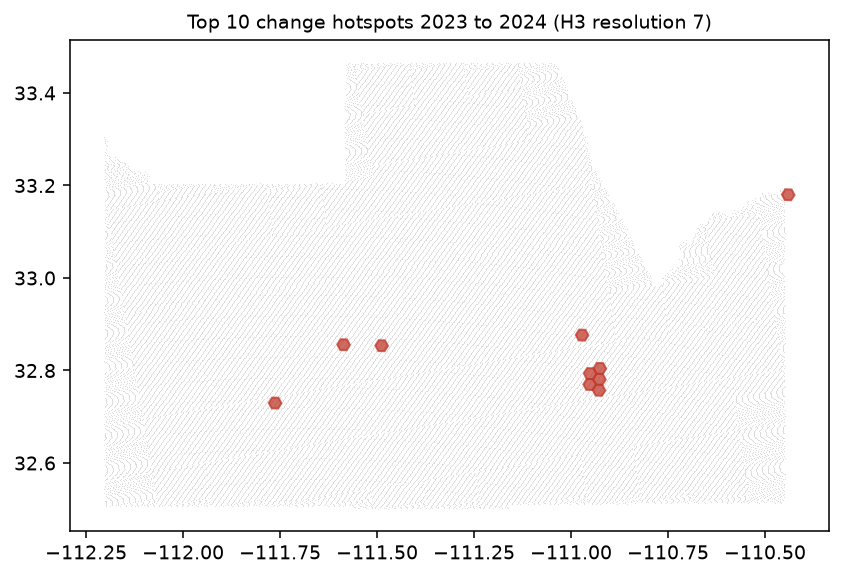

In [8]:
text = (ROOT / 'docs' / 'examples' / 'nonfarm_change.md').read_text()
keep = '\n'.join(l for l in text.split('## 5.')[0].splitlines() if not l.startswith('![map]'))
display(Markdown(keep))
display(Image(filename=str(ROOT / 'docs' / 'examples' / 'maps' / 'hotspots_top10_crop0.05.png'), width=560))

## Limitations

Accuracy is agreement with the CDL, which has its own errors. The figures come from a class-balanced sample of pure pixels, not a wall-to-wall map. One county, two years. See `docs/overview.md` for the full list.